# Logistic Regression

Core features used:

```
FEATURES = ["cancellation_rate","total_orders", "tenure_days",
            "recency_days", "frequency", "orders_30d", "orders_60d",
            "orders_90d", "month_orders", "month_revenue", "month_quantity",
            "month_diff_items", "month_cancellations"]
```



In [ ]:
import pandas as pd
import os
from google.colab import drive


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
feat = pd.read_csv("/content/drive/MyDrive/BTT_Amazon1A_Studio/feat.csv")

In [ ]:
feat.head()

,Customer ID,SnapshotMonth,month_orders,month_revenue,month_quantity,month_diff_items,month_last_order,month_cancellations,cancellation_rate,churn,snapshot_end,last_order,first_order,total_orders,tenure_days,recency_days,frequency,orders_30d,orders_60d,orders_90d
0,12346,2009-12,2.0,113.50,26.0,2.0,2009-12-18 10:55:00,0.0,0.000000,0,2009-12-31,2009-12-18 10:55:00,2009-12-14 08:34:00,5.0,16.0,12.0,5.0,5.0,5.0,5.0
1,14606,2009-12,11.0,1401.59,527.0,210.0,2009-12-21 14:33:00,12.0,1.090909,0,2009-12-31,2009-12-21 14:33:00,2009-12-03 12:40:00,8.0,27.0,9.0,8.0,8.0,8.0,8.0
2,14605,2009-12,1.0,208.60,133.0,31.0,2009-12-08 13:59:00,0.0,0.000000,1,2009-12-31,2009-12-08 14:01:00,2009-12-08 13:59:00,2.0,22.0,22.0,2.0,2.0,2.0,2.0
3,14593,2009-12,1.0,391.68,157.0,65.0,2009-12-09 12:57:00,2.0,2.000000,0,2009-12-31,2009-12-09 12:57:00,2009-12-09 12:57:00,1.0,21.0,21.0,1.0,1.0,1.0,1.0
4,14590,2009-12,3.0,349.66,108.0,38.0,2009-12-16 11:26:00,0.0,0.000000,0,2009-12-31,2009-12-16 11:26:00,2009-12-07 14:10:00,3.0,23.0,14.0,3.0,3.0,3.0,3.0


In [ ]:
feat.columns

Index(['Customer ID', 'SnapshotMonth', 'month_orders', 'month_revenue',
       'month_quantity', 'month_diff_items', 'month_last_order',
       'month_cancellations', 'cancellation_rate', 'churn', 'snapshot_end',
       'last_order', 'first_order', 'total_orders', 'tenure_days',
       'recency_days', 'frequency', 'orders_30d', 'orders_60d', 'orders_90d'],
      dtype='object')

In [ ]:
# Cleaning feat before splitting into training & testing
feat = feat.fillna(0)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Defining Train Set, extracting only features we want
FEATURES = ["cancellation_rate","total_orders", "tenure_days",
            "recency_days", "frequency", "orders_30d", "orders_60d",
            "orders_90d", "month_orders", "month_revenue", "month_quantity",
            "month_diff_items", "month_cancellations"]
X = feat[FEATURES]
y = feat['churn']

# Train/Test splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, random_state=42, stratify=y
)

## Baseline: Logistic Regression
**Model:** `LogisticRegression(max_iter=10000)`, tuned with 5-fold cross-validated grid search over `C`.

**Best hyperparameters:** `{'C': 100}`

**Best validation F1:** 0.3714

**Accuracy:** 0.7808

The F1 score is low, so this model is not doing a good job of catching churners. This is the baseline that later models need to beat.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV

# Parameters used in training to find best model
param_grid={
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
}


grid_search = GridSearchCV(
estimator = LogisticRegression(max_iter=2500, random_state=67),
param_grid=param_grid,
cv=5,
scoring='f1',
n_jobs=-1
)
grid_search.fit(X_train, y_train)

print(f"hyperparameters: {grid_search.best_params_}")
print(f"best validation f1 score: {grid_search.best_score_:.4f}")



hyperparameters: {'C': 100}
best validation f1 score: 0.3714


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
grid_search.estimator.fit(X_train, y_train)
y_pred = grid_search.estimator.predict(X_test)
acc_score = accuracy_score(y_test, y_pred)
print(acc_score)


0.7807765151515151


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Evaluating model

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc
)

In [ ]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")


Precision: 0.5149
Recall: 0.2752
F1: 0.3587


In [ ]:
y_probs = grid_search.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_probs)
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recalls, precisions)

print(f"ROC AUC: {roc_auc:.4f}")
print(f"PR AUC: {pr_auc:.4f}")

ROC AUC: 0.8160
PR AUC: 0.4950


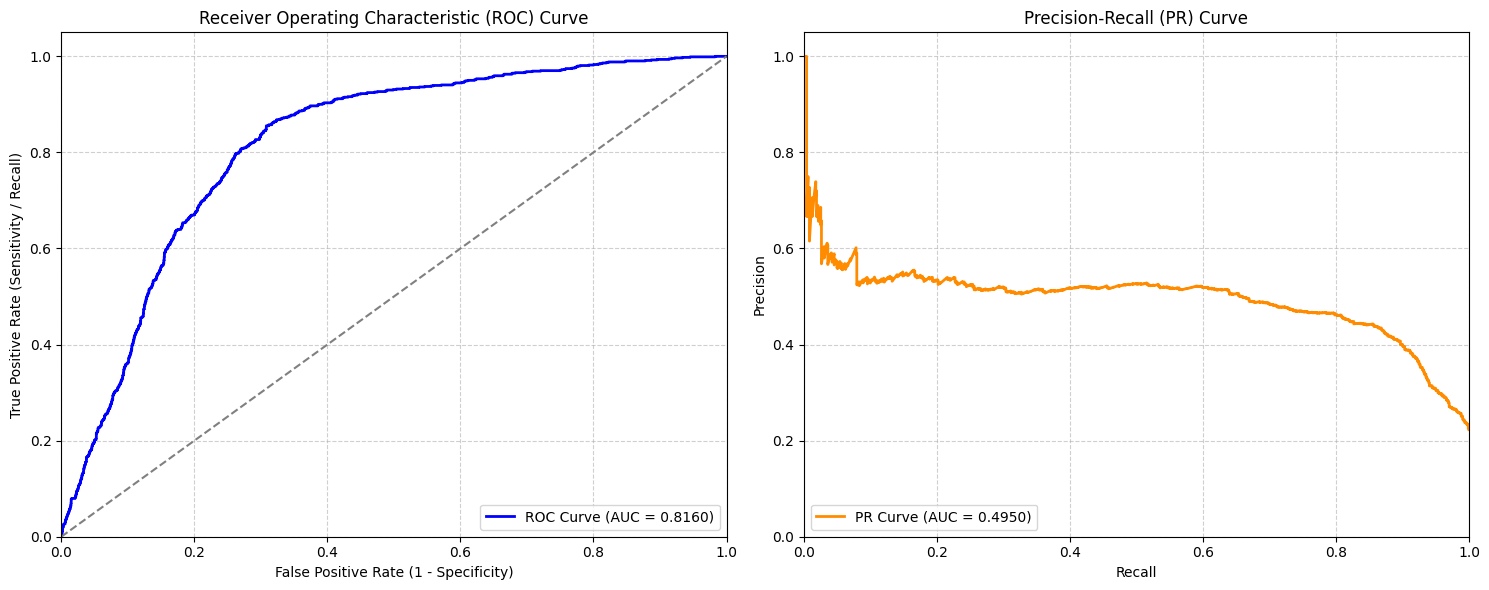

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# Calculate ROC curve values
fpr, tpr, roc_thresholds = roc_curve(y_test, y_probs)

# Create side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot ROC Curve
axes[0].plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Precision-Recall Curve
axes[1].plot(recalls, precisions, color='darkorange', lw=2, label=f'PR Curve (AUC = {pr_auc:.4f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall (PR) Curve')
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Finding the Optimal Threshold to Improve Recall

To increase the model's recall (the proportion of actual churners we catch as that is what we want to focus on), we can lower the classification threshold from the default `0.5`.

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Method 1: Target at least 80% recall from the PR Curve data
target_recall = 0.80
# Get indices where recall is at least 80%
re_indices = np.where(recalls >= target_recall)[0]
# Find the threshold associated with the highest precision in that subset
best_index = re_indices[np.argmax(precisions[re_indices])]
threshold_80_recall = thresholds[best_index] if best_index < len(thresholds) else thresholds[-1]

print(f"[Target 80% Recall]")
print(f"Suggested Threshold: {threshold_80_recall:.4f}")


[Target 80% Recall]
Suggested Threshold: 0.2457


Let's evaluate the performance on the test set using our new threshold targeting **80% Recall** vs the original default threshold.

In [ ]:
# Apply the target 80% recall threshold
y_pred_new = (y_probs >= threshold_80_recall).astype(int)

print("=== Classification Report (New Threshold) ===")
print(classification_report(y_test, y_pred_new))

print("=== Confusion Matrix ===")
cm = confusion_matrix(y_test, y_pred_new)
print(f"True Negatives (Correctly kept): {cm[0][0]}")
print(f"False Positives (Incorrectly flagged): {cm[0][1]}")
print(f"False Negatives (Missed churners): {cm[1][0]}")
print(f"True Positives (Caught churners): {cm[1][1]}")

=== Classification Report (New Threshold) ===
              precision    recall  f1-score   support

           0       0.93      0.73      0.82      3283
           1       0.46      0.80      0.59       941

    accuracy                           0.75      4224
   macro avg       0.70      0.77      0.70      4224
weighted avg       0.82      0.75      0.77      4224

=== Confusion Matrix ===
True Negatives (Correctly kept): 2407
False Positives (Incorrectly flagged): 876
False Negatives (Missed churners): 187
True Positives (Caught churners): 754


### Conclusion

- **Baseline Logistic Regression**: The initial model using the standard threshold of 0.5 returned an accuracy of **78.08%** but suffered from a low recall of **27.52%** and an F1-score of **0.3587**, making it ineffective for catching potential churners.
- **Optimized Classification Threshold**: By plotting the ROC and Precision-Recall curves, we identified that lowering the threshold to **0.2457** could improve performance.
- **Evaluation Outcomes at Optimized Threshold**:
  - **Recall** dramatically increased from **27.52% to 80.13%**, catching **754** out of 941 actual churners.
  - **Precision** only experienced a minimal decrease, settling at **46.26%**.
  - The **F1-score** rose significantly to **0.5865**.

**Next Steps**: Although tuning the threshold has made this baseline model more usable, we need to explore training more complex ensemble models (such as Random Forests or XGBoost) to push both precision and recall even higher.